In [2]:
# ============================================================
# File: notebooks/01_EDA.ipynb — Cell 1: Nạp dữ liệu
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib

# Thiết lập hiển thị đẹp
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 12

# Đường dẫn đến thư mục dữ liệu Beijing
data_dir = pathlib.Path("../data/beijing_raw/PRSA_Data_20130301-20170228")

# Nạp TẤT CẢ 12 trạm vào 1 DataFrame lớn
all_stations = []
for csv_file in sorted(data_dir.glob("*.csv")):
    df = pd.read_csv(csv_file)
    all_stations.append(df)
    print(f"  Loaded {csv_file.name}: {df.shape[0]:,} rows")

data = pd.concat(all_stations, ignore_index=True)
print(f"\n✅ Tổng cộng: {data.shape[0]:,} dòng × {data.shape[1]} cột")
print(f"📋 Các cột: {data.columns.tolist()}")

  Loaded PRSA_Data_Aotizhongxin_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Changping_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Dingling_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Dongsi_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Guanyuan_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Gucheng_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Huairou_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Nongzhanguan_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Shunyi_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Tiantan_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Wanliu_20130301-20170228.csv: 35,064 rows
  Loaded PRSA_Data_Wanshouxigong_20130301-20170228.csv: 35,064 rows

✅ Tổng cộng: 420,768 dòng × 18 cột
📋 Các cột: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']


In [3]:
# ============================================================
# Cell 2: Tạo cột datetime chuẩn
# ============================================================

# Dữ liệu Beijing lưu thời gian thành 4 cột riêng: year, month, day, hour
# Ta cần GỘP lại thành 1 cột datetime duy nhất để xử lý chuỗi thời gian

data["datetime"] = pd.to_datetime(
    data[["year", "month", "day", "hour"]]    # chọn 4 cột
    .astype(str)                               # chuyển thành chuỗi
    .agg("-".join, axis=1),                    # nối thành "2013-3-1-0"
    format="%Y-%m-%d-%H"                       # format tương ứng
)

# Đặt datetime làm index → thuận tiện cho mọi thao tác time series
data = data.set_index("datetime").sort_index()

# Kiểm tra
print(f"Khoảng thời gian: {data.index.min()} → {data.index.max()}")
print(f"Số trạm: {data['station'].nunique()} — {data['station'].unique()}")

Khoảng thời gian: 2013-03-01 00:00:00 → 2017-02-28 23:00:00
Số trạm: 12 — <StringArray>
[ 'Aotizhongxin',       'Tiantan',      'Dingling',        'Wanliu',
     'Changping',        'Shunyi',  'Nongzhanguan', 'Wanshouxigong',
       'Huairou',       'Gucheng',      'Guanyuan',        'Dongsi']
Length: 12, dtype: str


In [6]:
# ============================================================
# Cell 3: Thống kê mô tả
# ============================================================

# (A) Xem 5 dòng đầu tiên
print("═══ 5 dòng đầu ═══")
display(data.head())

# (B) Kiểu dữ liệu của từng cột
print("\n═══ Kiểu dữ liệu ═══")
print(data.dtypes)

# (C) Thống kê số — cho cái nhìn tổng quan NHANH NHẤT
print("\n═══ Thống kê mô tả ═══")
display(data.describe().round(2))

# (D) Missing values — CỰC KỲ QUAN TRỌNG
print("\n═══ Missing Values ═══")
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_df = pd.DataFrame({"Count": missing, "Percent (%)": missing_pct})
print(missing_df[missing_df["Count"] > 0].sort_values("Percent (%)", ascending=False))

═══ 5 dòng đầu ═══


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
datetime,,,,,,,,,,,,,,,,,,
2013-03-01,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01,1,2013,3,1,0,6.0,6.0,4.0,8.0,300.0,81.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Tiantan
2013-03-01,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling
2013-03-01,1,2013,3,1,0,8.0,8.0,6.0,28.0,400.0,52.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Wanliu
2013-03-01,1,2013,3,1,0,3.0,6.0,13.0,7.0,300.0,85.0,-2.3,1020.8,-19.7,0.0,E,0.5,Changping



═══ Kiểu dữ liệu ═══
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object

═══ Thống kê mô tả ═══


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.00,420768.00,420768.00,420768.00,420768.00,412029.00,414319.00,411747.00,408652.00,400067.00,407491.00,420370.00,420375.00,420365.00,420378.00,420450.00
mean,17532.50,2014.66,6.52,15.73,11.50,79.79,104.60,15.83,50.64,1230.77,57.37,13.54,1010.75,2.49,0.06,1.73
std,10122.12,1.18,3.45,8.80,6.92,80.82,91.77,21.65,35.13,1160.18,56.66,11.44,10.47,13.79,0.82,1.25
min,1.00,2013.00,1.00,1.00,0.00,2.00,2.00,0.29,1.03,100.00,0.21,-19.90,982.40,-43.40,0.00,0.00
25%,8766.75,2014.00,4.00,8.00,5.75,20.00,36.00,3.00,23.00,500.00,11.00,3.10,1002.30,-8.90,0.00,0.90
50%,17532.50,2015.00,7.00,16.00,11.50,55.00,82.00,7.00,43.00,900.00,45.00,14.50,1010.40,3.10,0.00,1.40
75%,26298.25,2016.00,10.00,23.00,17.25,111.00,145.00,20.00,71.00,1500.00,82.00,23.30,1019.00,15.10,0.00,2.20
max,35064.00,2017.00,12.00,31.00,23.00,999.00,999.00,500.00,290.00,10000.00,1071.00,41.60,1042.80,29.10,72.50,13.20



═══ Missing Values ═══
       Count  Percent (%)
CO     20701         4.92
O3     13277         3.16
NO2    12116         2.88
SO2     9021         2.14
PM2.5   8739         2.08
PM10    6449         1.53
wd      1822         0.43
DEWP     403         0.10
PRES     393         0.09
TEMP     398         0.09
RAIN     390         0.09
WSPM     318         0.08


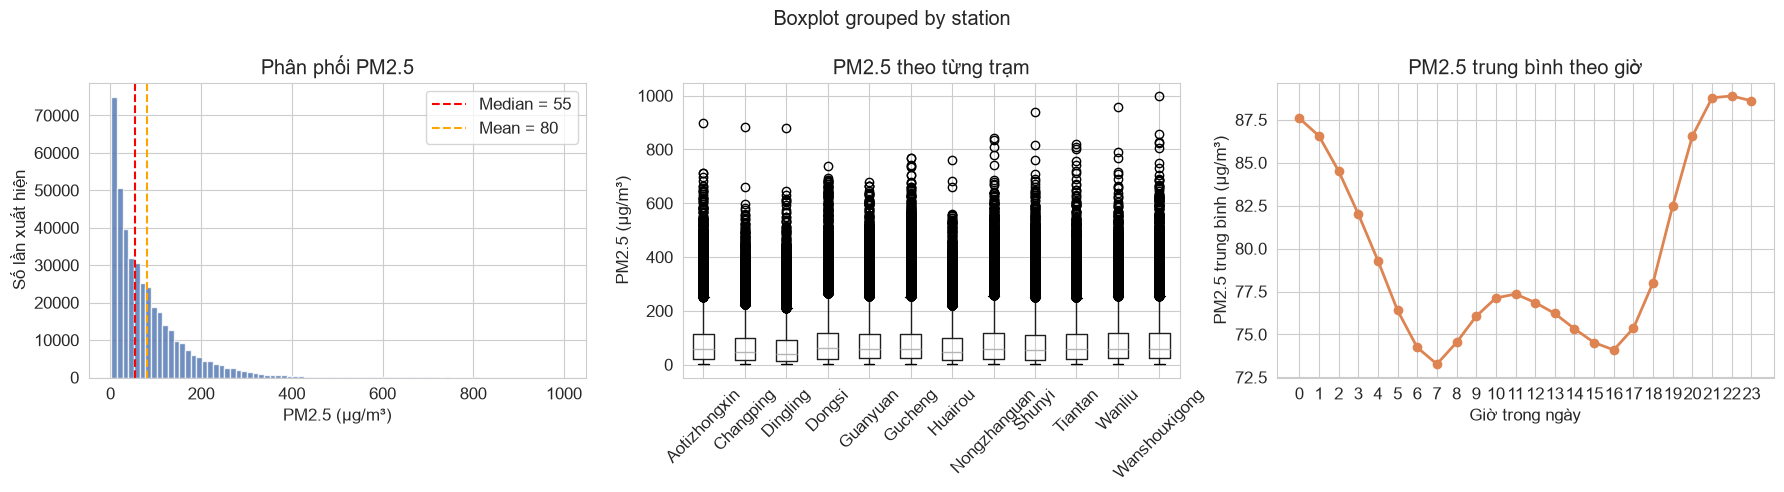

In [7]:
# ============================================================
# Cell 4: Trực quan hóa phân phối PM2.5
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (A) Histogram — phân phối tổng thể
axes[0].hist(data["PM2.5"].dropna(), bins=80, color="#4C72B0", edgecolor="white", alpha=0.8)
axes[0].axvline(data["PM2.5"].median(), color="red", linestyle="--", label=f'Median = {data["PM2.5"].median():.0f}')
axes[0].axvline(data["PM2.5"].mean(), color="orange", linestyle="--", label=f'Mean = {data["PM2.5"].mean():.0f}')
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_ylabel("Số lần xuất hiện")
axes[0].set_title("Phân phối PM2.5")
axes[0].legend()

# (B) Boxplot theo trạm — so sánh giữa các vị trí đo
data.boxplot(column="PM2.5", by="station", ax=axes[1], rot=45)
axes[1].set_title("PM2.5 theo từng trạm")
axes[1].set_xlabel("")
axes[1].set_ylabel("PM2.5 (µg/m³)")

# (C) PM2.5 trung bình theo giờ trong ngày — tìm pattern chu kỳ
hourly_mean = data.groupby(data.index.hour)["PM2.5"].mean()
axes[2].plot(hourly_mean.index, hourly_mean.values, "o-", color="#DD8452", linewidth=2)
axes[2].set_xlabel("Giờ trong ngày")
axes[2].set_ylabel("PM2.5 trung bình (µg/m³)")
axes[2].set_title("PM2.5 trung bình theo giờ")
axes[2].set_xticks(range(0, 24))

plt.tight_layout()
plt.savefig("../results/01_pm25_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

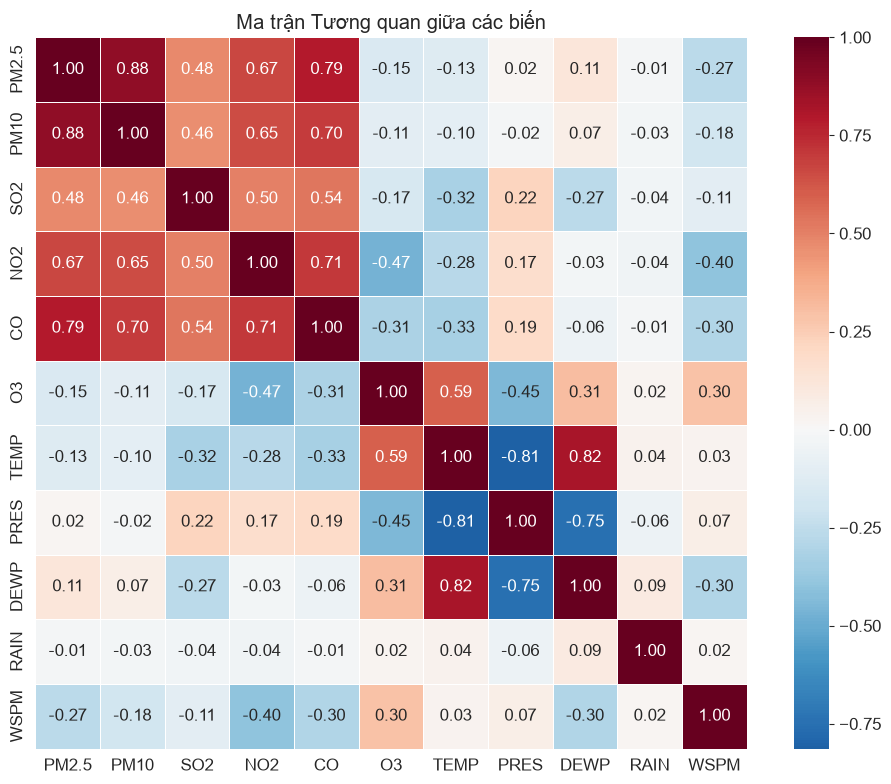

In [8]:
# ============================================================
# Cell 5: Ma trận tương quan (Correlation Matrix)
# ============================================================

# Chỉ chọn các cột số (numeric)
numeric_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

corr_matrix = data[numeric_cols].corr()

# Vẽ heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          # hiển thị giá trị số
    fmt=".2f",           # 2 chữ số thập phân
    cmap="RdBu_r",       # màu: đỏ = tương quan dương, xanh = âm
    center=0,            # 0 ở giữa thang màu
    square=True,
    linewidths=0.5
)
plt.title("Ma trận Tương quan giữa các biến")
plt.tight_layout()
plt.savefig("../results/01_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

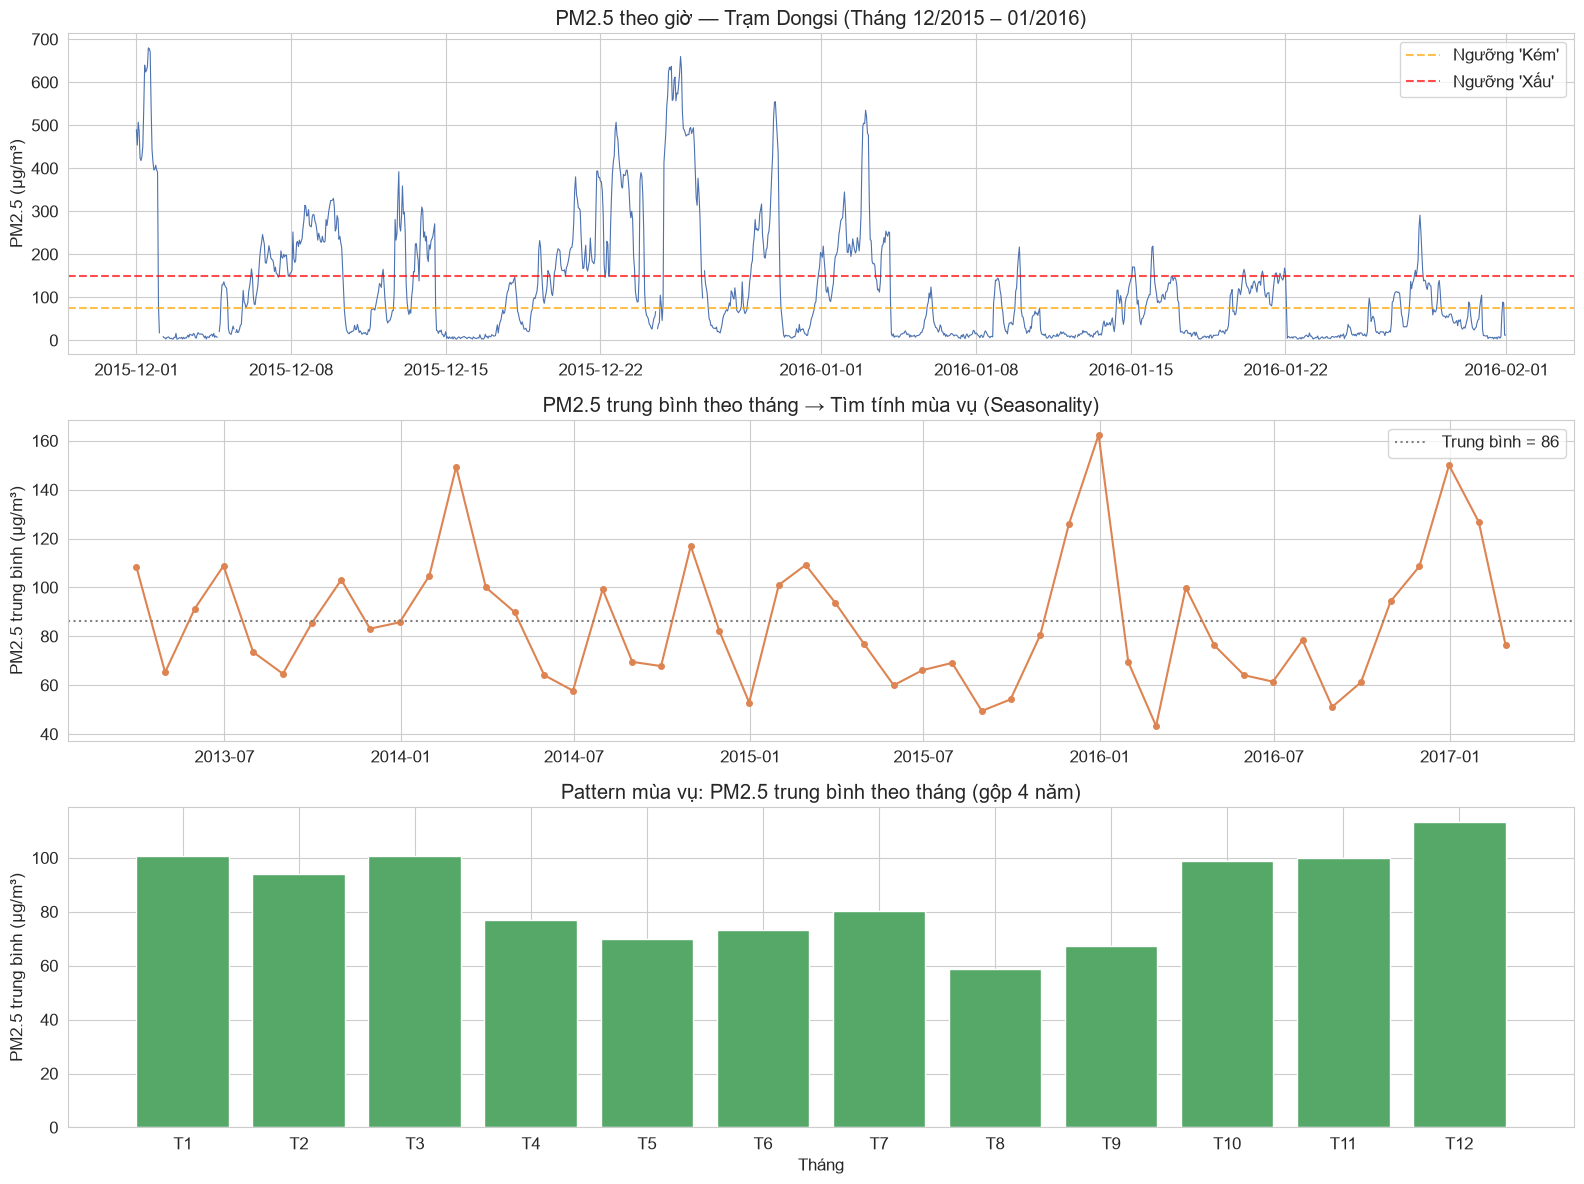

In [9]:
# ============================================================
# Cell 6: Trực quan hóa chuỗi thời gian
# ============================================================

# Chọn 1 trạm để phân tích chi tiết
station_data = data[data["station"] == "Dongsi"].copy()

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=False)

# (A) Chuỗi PM2.5 gốc — 1 tháng
one_month = station_data["2015-12":"2016-01"]
axes[0].plot(one_month.index, one_month["PM2.5"], linewidth=0.8, color="#4C72B0")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("PM2.5 theo giờ — Trạm Dongsi (Tháng 12/2015 – 01/2016)")
axes[0].axhline(y=75, color="orange", linestyle="--", alpha=0.7, label="Ngưỡng 'Kém'")
axes[0].axhline(y=150, color="red", linestyle="--", alpha=0.7, label="Ngưỡng 'Xấu'")
axes[0].legend()

# (B) Trung bình theo tháng — tìm tính mùa vụ
monthly = station_data["PM2.5"].resample("ME").mean()
axes[1].plot(monthly.index, monthly.values, "o-", color="#DD8452", markersize=4)
axes[1].set_ylabel("PM2.5 trung bình (µg/m³)")
axes[1].set_title("PM2.5 trung bình theo tháng → Tìm tính mùa vụ (Seasonality)")
axes[1].axhline(y=monthly.mean(), color="gray", linestyle=":", label=f"Trung bình = {monthly.mean():.0f}")
axes[1].legend()

# (C) PM2.5 trung bình theo tháng trong năm (gộp tất cả các năm)
monthly_pattern = station_data.groupby(station_data.index.month)["PM2.5"].mean()
axes[2].bar(monthly_pattern.index, monthly_pattern.values, color="#55A868", edgecolor="white")
axes[2].set_xlabel("Tháng")
axes[2].set_ylabel("PM2.5 trung bình (µg/m³)")
axes[2].set_title("Pattern mùa vụ: PM2.5 trung bình theo tháng (gộp 4 năm)")
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"])

plt.tight_layout()
plt.savefig("../results/01_time_series.png", dpi=150, bbox_inches="tight")
plt.show()